# Linear regression model

In [19]:
import numpy as np

class LinearRegression:

    def __init__(self, lr = 0.001, n_iters = 1000): #we are setting initial values which can change
        self.lr = lr
        self.n_iters = n_iters
        self.weights = None
        self.bias = None

    #for model training:
    def fit(self, X, y):
      n_samples, n_features = X.shape #get number of samples and features
      self.weights = np.zeros(n_features); #only 1 weight for each feature
      self.bias = 0


      for _ in range(self.n_iters):
          y_pred = np.dot(X, self.weights) + self.bias

          #derivatives and gradients dJ/dw and dJ/db
          dw=(1/n_samples)*np.dot(X.T, (y_pred-y)) #np.dot includes the sumation (!!!!)
                                                   #X.T here is to get the transpose of X
          dj=(1/n_samples)*np.sum(y_pred-y)


          #update weights and bias
          self.weights = self.weights - self.lr * dw # w = w - a*dw
          self.bias = self.bias - self.lr * dj  # b = b - a*dj

    #we doing predictions for al samples at the same time with an array for "ypred"
    def predict(self, X):
      y_pred = np.dot(X, self.weights) + self.bias
      return y_pred






# Trying the model

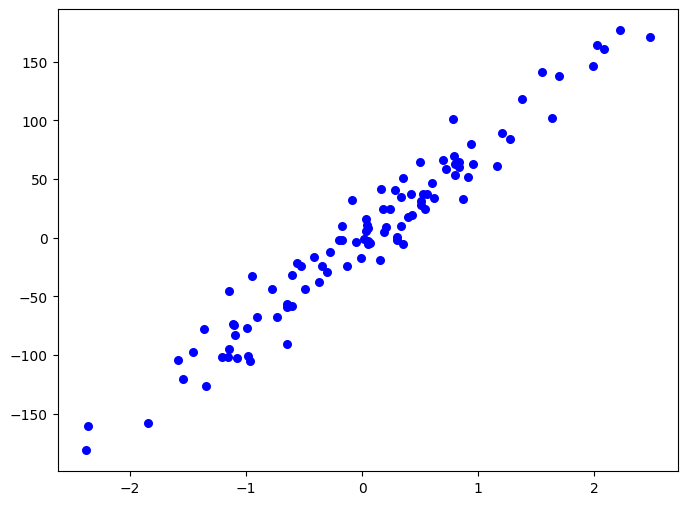

In [17]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn import datasets
import matplotlib.pyplot as plt
#from LinearRegression import LinearRegression #--> use when it is in another file

# Generate synthetic data for regression
X, y = datasets.make_regression(n_samples = 100, n_features = 1, noise = 20, random_state = 4)
# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 1234)

# Visualize the dataset (entire data):
fig = plt.figure(figsize = (8,6))
plt.scatter(X[:,0], y, color = "b", marker ="o", s=30)
plt.show()

mean squared error = 305.7719958301902


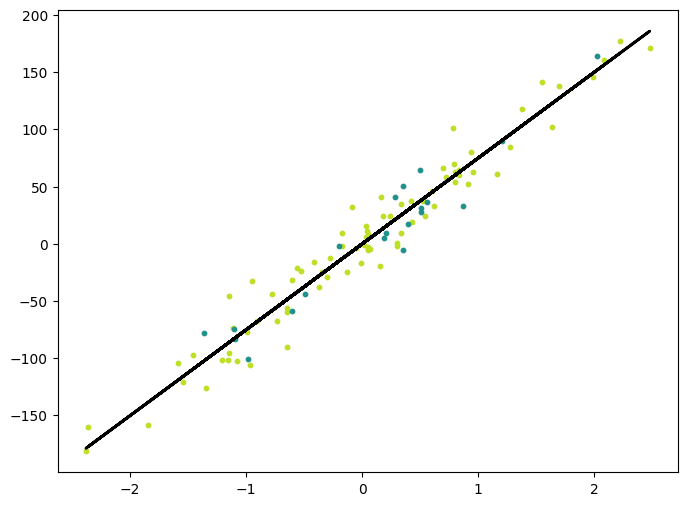

In [31]:
### fitting the model to the data by calling the class in the instance (self)
reg = LinearRegression(lr=0.01) ## you can modify the learning rate (lr)
reg.fit(X_train, y_train)

# Make predictions on the test set
predictions = reg.predict(X_test)


# Mean Squared Error function
def mse(y_test, predictions):
  return np.mean((y_test - predictions)**2) #squared root

mse_value = mse(y_test, predictions)
print("mean squared error =", mse_value)


# Plotting the regression line along with training and test data
y_pred_line = reg.predict(X) #predict over entire dataser
cmap = plt.get_cmap("viridis")
fig = plt.figure(figsize = (8,6))
m1 = plt.scatter(X_train, y_train, color=cmap(0.9), s=10, label="Training data")
m2 = plt.scatter(X_test, y_test, color=cmap(0.5), s=10, label="Test data")

plt.plot(X, y_pred_line, color="black", linewidth =2, label= "prediction")
plt.show()

Why X and X_test?

X_train and y_train: The portion of the data used for training the model.

X_test and y_test: The portion of the data used for testing the model's performance (to evaluate how well it generalizes to new, unseen data).

X: This represents the entire dataset, including both training and test data. When you use X in reg.predict(), you are predicting for the entire dataset.

In summary, you're training the model with X_train and y_train, then evaluating its performance on X_test and y_test. Later, you use X (the entire dataset) to visualize the regression line.

4. Plotting and Evaluation:
After you fit the model, you calculate the mean squared error (MSE) to evaluate how far off the predictions are from the actual y_test values:

python
Copy code
mse_value = mse(y_test, predictions)
This gives a numerical measure of the error between the predicted and actual test data values.

5. Graphing the Regression Line:
You are plotting both the training and test data along with the regression line. You use the entire dataset X to plot the regression line. This is fine, as you're visualizing how the line fits the data:

python
Copy code
plt.plot(X, y_pred_line, color="black", linewidth=2, label="prediction")

# Formulas and instructions

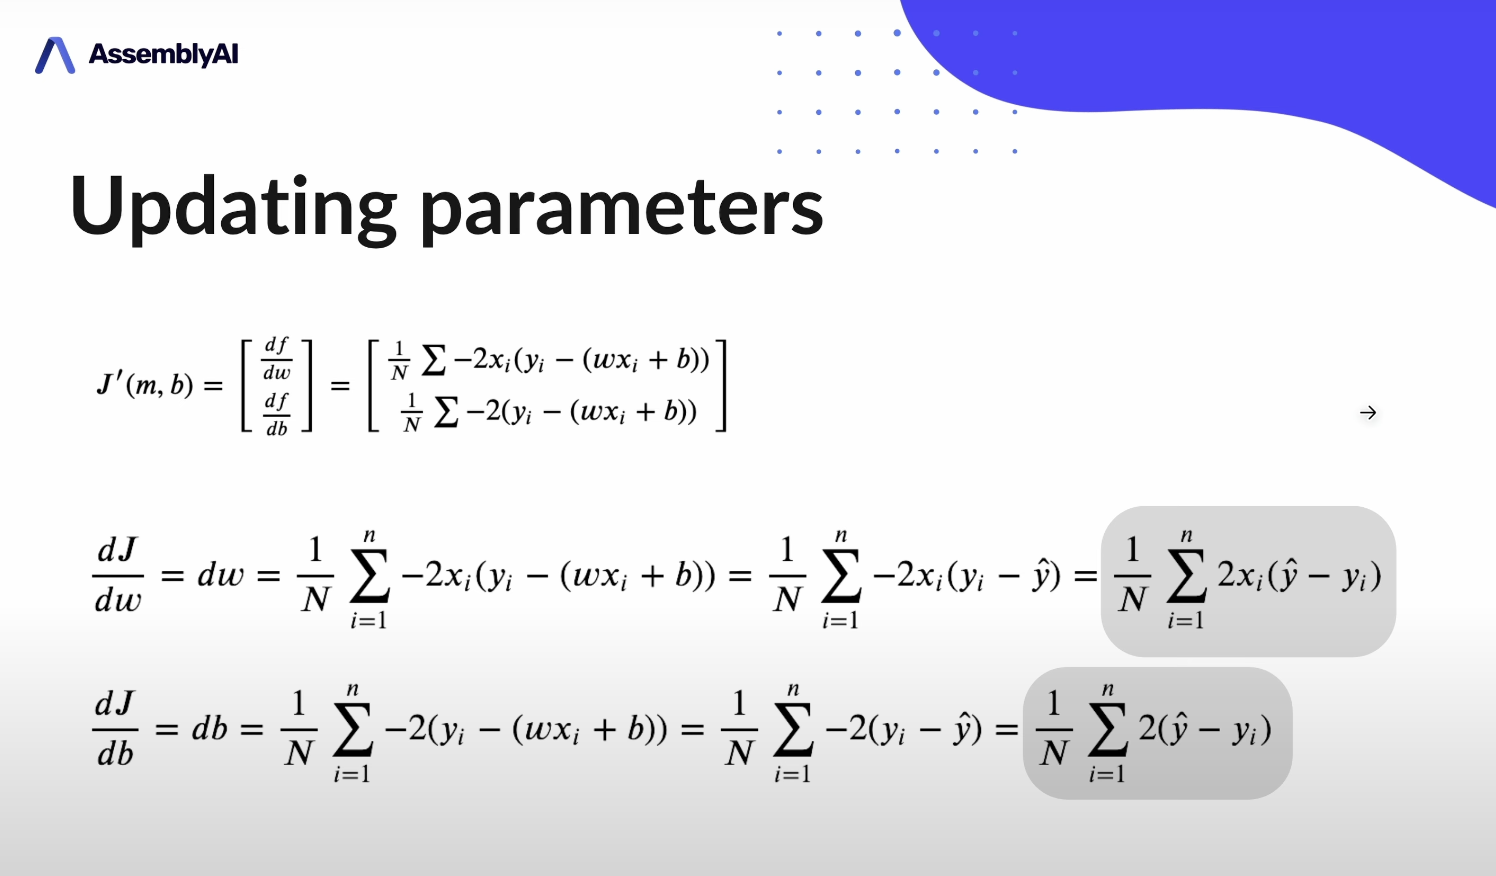

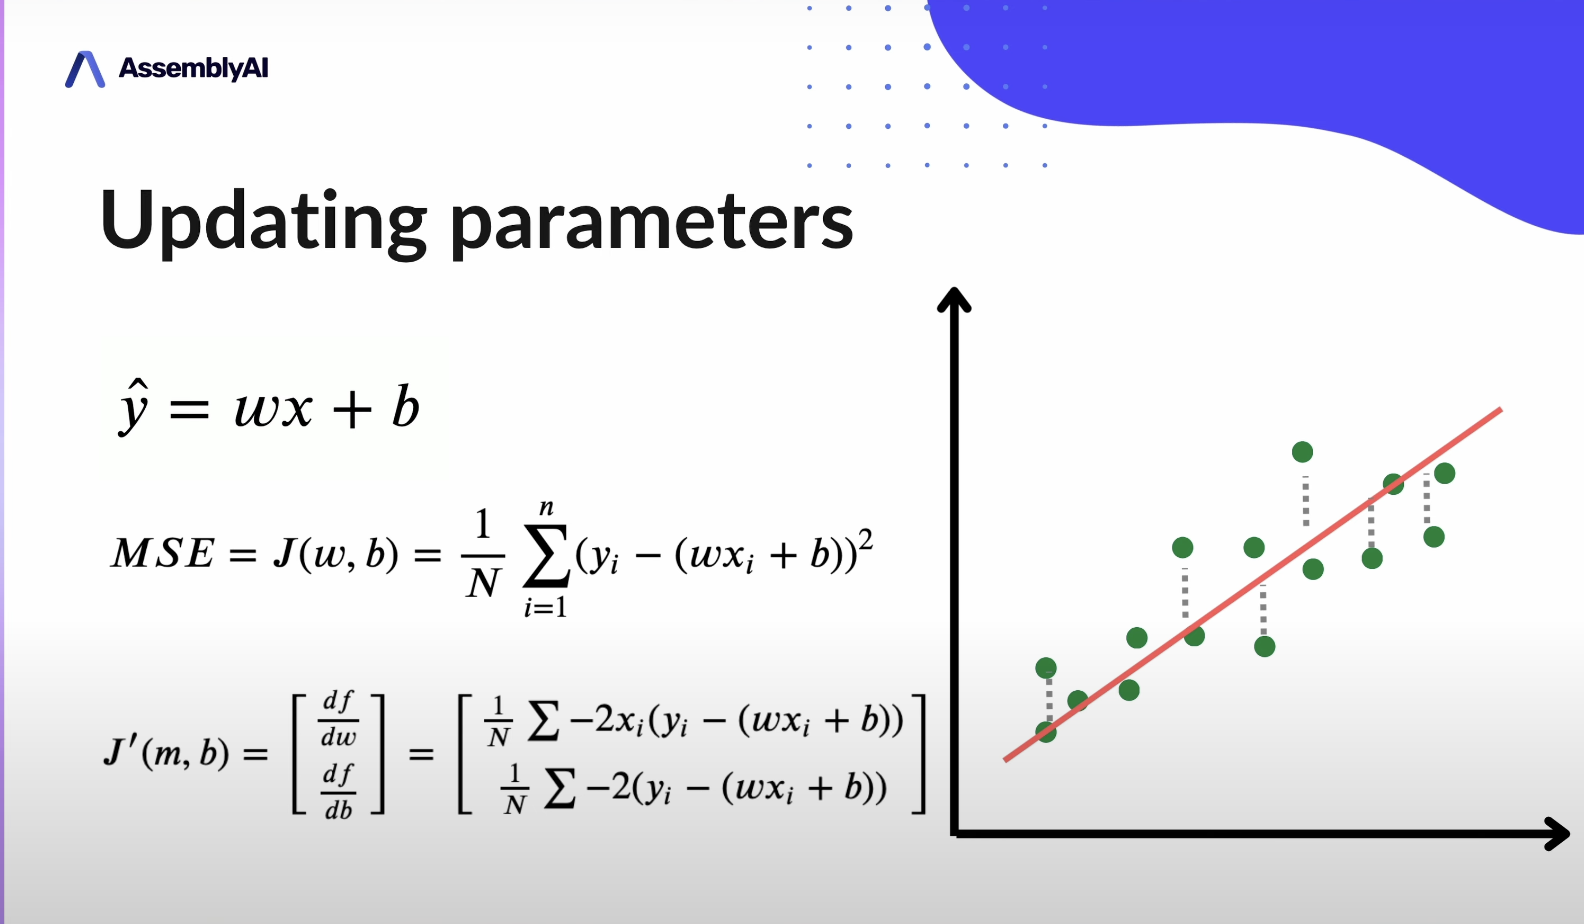

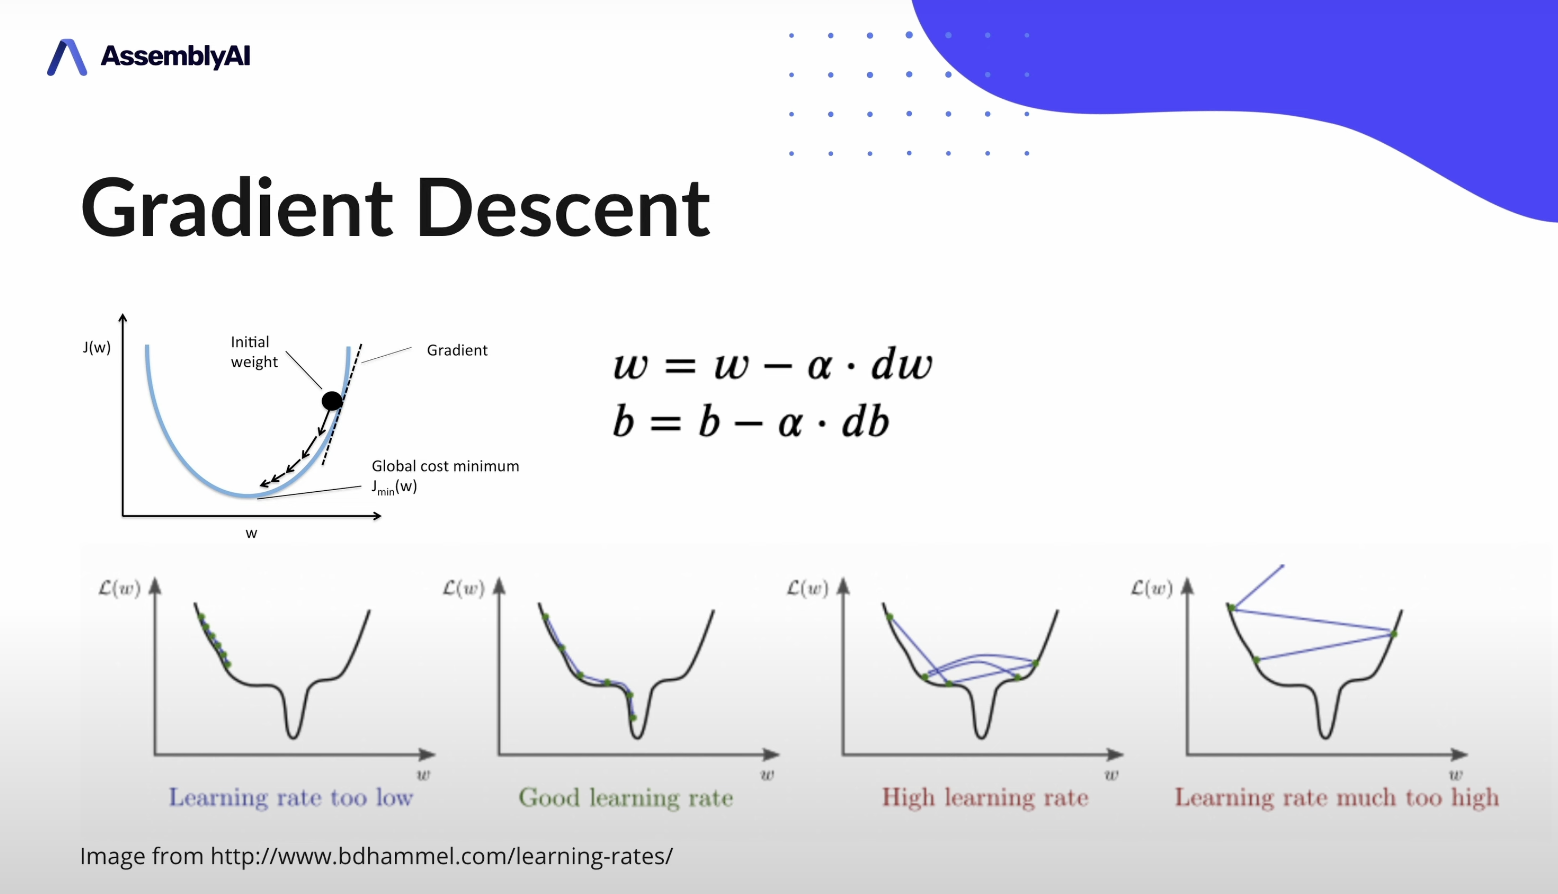